# Parte 1 — Extracción y limpieza de datos

**Dataset:** `leads_ventas.csv` — simulación de tabla Oracle legada con 5,250 registros (incluye duplicados intencionales), datos sucios en fuente y sala, y nulos en varios campos.

**Objetivo:** limpiar, normalizar y enriquecer el dataset para que sea usable en análisis y modelos de propensión.

**Fases:**
1. Carga y exploración — entender la estructura y calidad del dato.
2. Limpieza — normalizar, imputar y eliminar duplicados.
3. Enriquecimiento — columnas derivadas y métricas de negocio.

---

## Fase 1 — Carga y exploración

### Celda 1 — Importaciones

Se cargan las librerías necesarias para el análisis:
- `pandas` / `numpy`: manipulación de datos.
- `matplotlib` / `seaborn`: visualizaciones.
- `missingno`: mapa visual de valores nulos (muy útil para detectar patrones de ausencia).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
%matplotlib inline

### Celda 2 — Carga del CSV

Se lee el archivo `leads_ventas.csv` parseando automáticamente las columnas de fecha. El parámetro `parse_dates` convierte `fecha_creacion` y `fecha_venta` a tipo `datetime64`, lo que permite operar sobre ellas directamente (extraer mes, calcular diferencias, etc.).

> **Nota:** si el archivo no está en `../data/`, ajusta la ruta según tu estructura de carpetas.

In [2]:
df = pd.read_csv("../data/leads_ventas.csv",
                 parse_dates=["fecha_creacion", "fecha_venta"])
print("Shape:", df.shape)
df.head()

Shape: (5250, 8)


,lead_id,fuente,fecha_creacion,fecha_venta,monto,vpg,sala,comentarios
0,100000,NaN,2023-04-25,2023-05-31,NaN,1546.53,cancún,Cliente molesto por llamadas repetidas.
1,100001,PROVEEDOR A,2024-08-27,2024-08-31,37018.38,NaN,cabo,"Muy interesado, agendar presentación."
2,100002,NaN,2024-10-27,NaT,NaN,NaN,PV,Solicitó cancelar su registro.
3,100003,social,2023-01-07,NaT,NaN,NaN,CANCÚN,Ya había hecho tour antes.
4,100004,social,2023-06-09,2023-07-23,39019.41,3349.45,Puerto Vallarta,NaN


### Celda 3 — Estructura y tipos de datos

`df.info()` muestra cuántas filas hay, el tipo de dato de cada columna y si hay nulos implícitos. `df.describe(include='all').T` da estadísticos descriptivos de cada columna (media, mínimo, máximo, frecuencia en categóricas). Juntos permiten hacer un primer diagnóstico completo del dataset.

In [3]:
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   lead_id         5250 non-null   int64         
 1   fuente          4589 non-null   str           
 2   fecha_creacion  5250 non-null   datetime64[us]
 3   fecha_venta     3134 non-null   datetime64[us]
 4   monto           2783 non-null   float64       
 5   vpg             2804 non-null   float64       
 6   sala            5250 non-null   str           
 7   comentarios     3695 non-null   str           
dtypes: datetime64[us](2), float64(2), int64(1), str(3)
memory usage: 328.3 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
lead_id,5250.0,NaN,NaN,NaN,102498.780381,100000.0,101249.25,102498.5,103750.75,104999.0,1444.592715
fuente,4589,20,Hotel,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_creacion,5250,NaN,NaN,NaN,2024-01-02 17:41:29.142857,2023-01-01 00:00:00,2023-07-05 00:00:00,2024-01-05 00:00:00,2024-07-03 00:00:00,2024-12-31 00:00:00,NaN
fecha_venta,3134,NaN,NaN,NaN,2024-02-10 18:43:25.232929,2023-01-04 00:00:00,2023-08-17 00:00:00,2024-02-17 00:00:00,2024-08-07 00:00:00,2025-03-21 00:00:00,NaN
monto,2783.0,NaN,NaN,NaN,132393.56673,15012.11,72368.37,132209.85,191467.53,249831.38,67890.907862
vpg,2804.0,NaN,NaN,NaN,4234.602803,504.02,2312.96,4204.24,6158.7625,7993.23,2188.405705
sala,5250,10,Playa del Carmen,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
comentarios,3695,10,Solicitó cotización para 2 adultos y 2 niños.,415,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Celda 4 — Cuantificación de nulos por columna

Se construye una tabla con el conteo absoluto y el porcentaje de nulos por columna, ordenada de mayor a menor. Esto permite priorizar qué columnas necesitan tratamiento urgente y cuáles son aceptables.

> **Interpretación esperada:** `fecha_venta`, `monto` y `vpg` tendrán ~40-47% de nulos (leads sin venta cerrada, lo cual es información válida, no un error).

In [4]:
nulos = df.isnull().sum().to_frame("nulos")
nulos["pct"] = (nulos["nulos"] / len(df) * 100).round(2)
nulos.sort_values("pct", ascending=False)

,nulos,pct
monto,2467,46.99
vpg,2446,46.59
fecha_venta,2116,40.30
comentarios,1555,29.62
fuente,661,12.59
lead_id,0,0.00
fecha_creacion,0,0.00
sala,0,0.00


### Celda 5 — Mapa visual de nulos (`missingno`)

El gráfico de `missingno.matrix()` muestra los nulos como líneas blancas sobre fondo negro. Si los nulos de varias columnas aparecen alineados en las mismas filas, significa que están correlacionados (los registros sin venta no tienen monto ni VPG — patrón esperado). Si los nulos son aleatorios y dispersos, el patrón es distinto.

> **Lo que buscamos:** confirmar que los nulos de `monto`/`vpg` coinciden exactamente con los de `fecha_venta`.

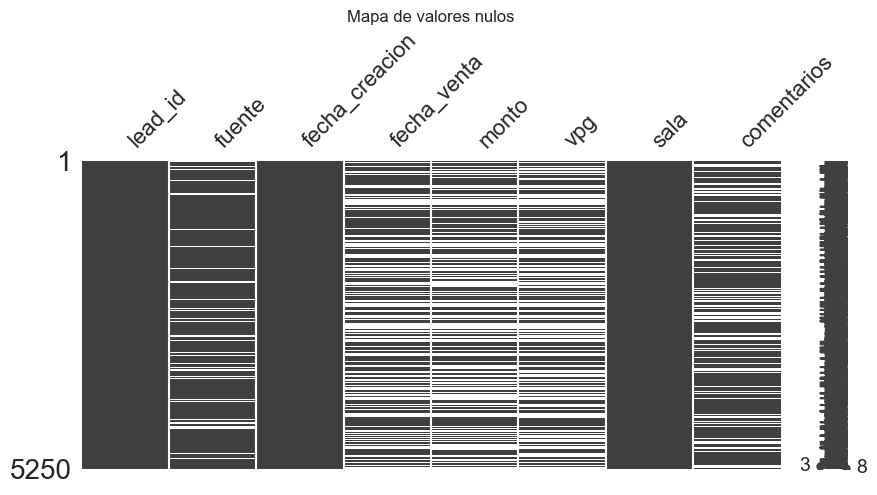

In [5]:
msno.matrix(df, figsize=(10, 4))
plt.title("Mapa de valores nulos")
plt.show()

### Celda 6 — Detección de duplicados

Se verifican duplicados a distintos niveles de granularidad:
- **Exactos** (todas las columnas iguales): copias idénticas del registro, claramente eliminables.
- **Por `lead_id`**: un mismo lead que aparece más de una vez (puede ser transferencia entre salas).
- **Por `lead_id` + `sala`**: mismo lead en la misma sala — definitivamente duplicado.

> El dataset fue generado con un 5% de duplicados intencionales (~250 filas), por lo que se esperan esos valores.

In [6]:
print("Total de filas:", len(df))
print("Duplicados exactos:", df.duplicated().sum())
print("lead_id duplicados:", df.duplicated(subset=["lead_id"]).sum())
print("lead_id + sala duplicados:", df.duplicated(subset=["lead_id", "sala"]).sum())
print("lead_id + fecha_creacion duplicados:", df.duplicated(subset=["lead_id", "fecha_creacion"]).sum())

Total de filas: 5250
Duplicados exactos: 250
lead_id duplicados: 250
lead_id + sala duplicados: 250
lead_id + fecha_creacion duplicados: 250


### Celda 7 — Valores únicos en `fuente` y `sala`

Se imprime el conteo de cada valor único para las dos columnas categóricas clave. El objetivo es identificar cuántas variantes del mismo concepto existen por inconsistencia de captura (mayúsculas, abreviaciones, tildes). Por ejemplo: `'Proveedor A'`, `'proveedor a'`, `'PROVEEDOR A'` y `'ProveedorA'` son el mismo canal.

> Esta celda es el insumo directo para construir el mapa de normalización de la Fase 2.

In [7]:
for col in ["fuente", "sala"]:
    print(f"\n{'='*50}")
    print(f"Columna: {col} — {df[col].nunique()} valores únicos")
    print('='*50)
    print(df[col].value_counts(dropna=False))


Columna: fuente — 20 valores únicos
fuente
NaN            661
Hotel          260
Social         258
Proveedor A    254
calle          248
Facebook       242
Calle TMS      239
proveedor a    236
PORTAL WEB     235
hotel          233
portal web     228
social         227
Portal Web     227
Calle          226
rci            224
OTA            220
ota            210
FB             208
PROVEEDOR A    207
ProveedorA     207
RCI            200
Name: count, dtype: int64

Columna: sala — 10 valores únicos
sala
Playa del Carmen    551
cabo                541
Los Cabos           538
CANCÚN              533
PV                  532
Puerto Vallarta     527
PDC                 519
Cabo                516
cancún              508
Cancún              485
Name: count, dtype: int64


### Celda 8 — Distribuciones de `monto` y `vpg`

Histogramas de las dos variables numéricas continuas del dataset. Se espera una distribución plana y uniforme en ambos casos (el script generador usó `random.uniform`), lo que confirma que no hay outliers extremos ni sesgo. Si hubiera barras muy altas en los extremos, indicaría datos atípicos que habría que tratar.

> **`monto`:** rango esperado $15,000 – $250,000 MXN.  
> **`vpg`:** rango esperado $500 – $8,000 MXN (valor por venta generado).

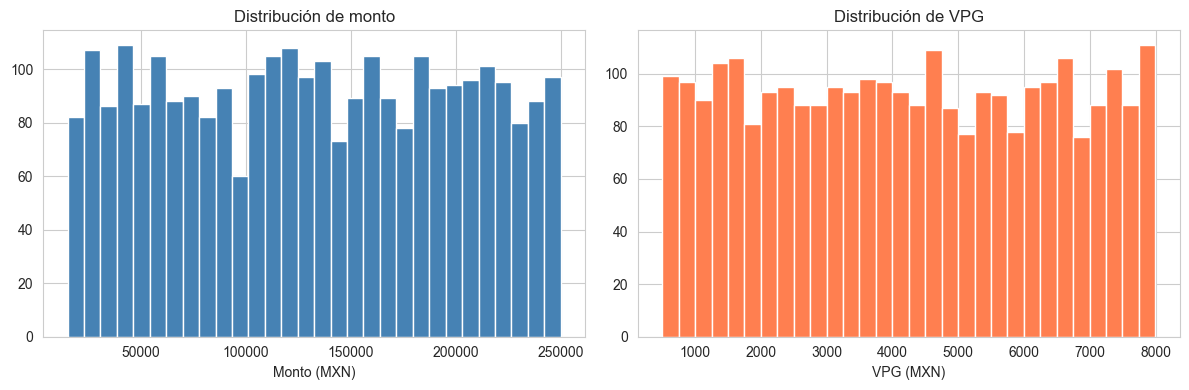

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["monto"].hist(ax=axes[0], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Distribución de monto")
axes[0].set_xlabel("Monto (MXN)")
df["vpg"].hist(ax=axes[1], bins=30, color="coral", edgecolor="white")
axes[1].set_title("Distribución de VPG")
axes[1].set_xlabel("VPG (MXN)")
plt.tight_layout()
plt.show()

### Celda 9 — Tasa de conversión preliminar por fuente (PRE-limpieza)

Se calcula cuántos leads de cada fuente terminaron en venta (`fecha_venta` no nula). **Esta métrica aún está distorsionada** porque `fuente` tiene 20 variantes sucias del mismo valor. El propósito de esta celda es mostrar el problema: la misma fuente aparece con tasas de conversión distintas solo porque está escrita de forma diferente.

> Esta celda se repite en la Fase 3 **después** de la limpieza para obtener la métrica real.

In [9]:
conversion = df.groupby("fuente", dropna=False).agg(
    leads=("lead_id", "count"),
    ventas=("fecha_venta", lambda x: x.notna().sum())
)
conversion["tasa_conversion"] = (conversion["ventas"] / conversion["leads"]).round(3)
conversion.sort_values("tasa_conversion", ascending=False)

,leads,ventas,tasa_conversion
fuente,,,
FB,208,139,0.668
Hotel,260,165,0.635
Social,258,163,0.632
hotel,233,146,0.627
Portal Web,227,140,0.617
proveedor a,236,145,0.614
ota,210,129,0.614
calle,248,152,0.613
Calle,226,136,0.602


### Celda 10 — Resumen de hallazgos de la Fase 1 y plan de acción

Esta celda consolida todo lo observado en la exploración. Sirve como documento de decisiones: qué se encontró, por qué se hace cada transformación y qué se deja intacto. Es la justificación técnica de la Fase 2.

### Mapa de nulos — Interpretación

- `lead_id`, `fecha_creacion`, `sala` → sin nulos.
- `fuente` (12.6%) y `comentarios` (29.6%) → nulos aleatorios dispersos.
- `fecha_venta` (40.3%) → patrón de bloque; corresponde a leads no convertidos (información válida, NO se imputa).
- `monto` y `vpg` (≈47%) → sus nulos están correlacionados entre sí (mismo patrón visual).
- **Problema detectado:** hay filas con `fecha_venta` presente pero `monto`/`vpg` nulos → ventas sin valor capturado. Se tratarán en la Fase 2 con imputación por mediana de sala.

### Duplicados
- 250 duplicados exactos (5% del total).
- lead_id + sala + fecha_creacion coinciden → son copias idénticas en la misma sala.
- **Regla:** `drop_duplicates()` sin pérdida de información.

### Categorías a normalizar
**`fuente` (20 únicos → 7 reales):**
- Proveedor A ← {Proveedor A, proveedor a, PROVEEDOR A, ProveedorA}
- Portal Web ← {Portal Web, portal web, PORTAL WEB}
- Social ← {Social, social, Facebook, FB}
- Calle ← {Calle, calle, Calle TMS}
- RCI ← {RCI, rci}
- OTA ← {OTA, ota}
- Hotel ← {Hotel, hotel}
- Desconocido ← {NaN}

**`sala` (10 únicos → 4 reales):**
- Cancún ← {Cancún, cancún, CANCÚN}
- Playa del Carmen ← {Playa del Carmen, PDC}
- Puerto Vallarta ← {Puerto Vallarta, PV}
- Los Cabos ← {Los Cabos, Cabo, cabo}


### Distribuciones (Celda 9)
- `monto`: distribución uniforme entre $15,000 y $250,000. Sin outliers ni sesgo.
- `vpg`: distribución uniforme entre $500 y $8,000. Sin outliers ni sesgo.
- No se requiere winsorización ni tratamiento de extremos.

### Conversión por fuente (Celda 10 — pre-limpieza)
- La fragmentación de categorías hace que las tasas aparezcan dispersas.
- Ejemplo: "Proveedor A" aparece en 4 variantes con tasas entre 0.522 y 0.614.
- Al normalizar se obtendrá una sola métrica por fuente, permitiendo comparación real.
- El grupo NaN presenta tasa 0.592 → cercana al promedio general. Se rellenará con "Desconocido".

### Resumen de acciones para la Fase 2
1. Eliminar 250 duplicados exactos.
2. Normalizar `fuente` (20 → 7 categorías).
3. Normalizar `sala` (10 → 4 categorías).
4. Rellenar nulos en `fuente` → "Desconocido" y `comentarios` → "Sin comentarios".
5. Imputar `monto` y `vpg` con mediana por sala SOLO donde haya `fecha_venta` no nula.
6. Dejar `fecha_venta` nula como está (indica lead no convertido).

### Duplicados
- 250 duplicados exactos (5% del total).
- lead_id + sala + fecha_creacion coinciden → son copias idénticas en la misma sala.
- **Regla:** `drop_duplicates()` sin pérdida de información.

### Categóricas a normalizar
**`fuente` (20 únicos → 7 reales):**
- Proveedor A ← {Proveedor A, proveedor a, PROVEEDOR A, ProveedorA}
- Portal Web ← {Portal Web, portal web, PORTAL WEB}
- Social ← {Social, social, Facebook, FB}
- Calle ← {Calle, calle, Calle TMS}
- RCI ← {RCI, rci}
- OTA ← {OTA, ota}
- Hotel ← {Hotel, hotel}
- Desconocido ← {NaN}

**`sala` (10 únicos → 4 reales):**
- Cancún ← {Cancún, cancún, CANCÚN}
- Playa del Carmen ← {Playa del Carmen, PDC}
- Puerto Vallarta ← {Puerto Vallarta, PV}
- Los Cabos ← {Los Cabos, Cabo, cabo}

---

## Fase 2 — Limpieza

Con base en el diagnóstico de la Fase 1, se aplican cinco transformaciones en orden:

1. **Normalización de `fuente`** — 20 variantes → 8 categorías canónicas.
2. **Normalización de `sala`** — 10 variantes → 4 categorías canónicas.
3. **Imputación de nulos** — sin eliminar registros válidos.
4. **Eliminación de duplicados exactos** — 250 copias idénticas.
5. **Validaciones post-limpieza** — aserciones automáticas que verifican la calidad del resultado.

### Celda 11 — Normalización de `fuente`

Estrategia en dos pasos:
1. **`normalizar_texto()`**: convierte a minúsculas, elimina espacios extra y quita acentos. Esto hace que `'Proveedor A'`, `'PROVEEDOR A'` y `'proveedor a'` queden como `'proveedor a'`.
2. **`mapa_fuente`**: diccionario que mapea cada valor normalizado a su categoría canónica. Los valores que no están en el mapa (nulos, vacíos, `'N/A'`) se rellenan con `'Desconocido'`.

> Al final, `fuente` pasa de 20 valores únicos a 8 categorías limpias y comparables.

In [10]:
import unicodedata

def normalizar_texto(s):
    """Limpia un string: minúsculas, sin espacios extra, sin acentos."""
    if pd.isna(s):
        return s
    s = str(s).strip().lower()
    s = ''.join(c for c in unicodedata.normalize('NFD', s)
                if unicodedata.category(c) != 'Mn')
    return s

# Mapa: valor normalizado (minúsculas sin acentos) → categoría canónica
mapa_fuente = {
    "proveedor a":  "Proveedor A",
    "proveedora":   "Proveedor A",
    "portal web":   "Portal Web",
    "social":       "Social",
    "facebook":     "Social",
    "fb":           "Social",
    "calle":        "Calle",
    "calle tms":    "Calle",
    "rci":          "RCI",
    "ota":          "OTA",
    "hotel":        "Hotel",
}

# Aplicar
df["fuente_norm"] = df["fuente"].apply(normalizar_texto).map(mapa_fuente)

# Rellenar los que no mapearon (nulos, "", "N/A") con "Desconocido"
df["fuente_norm"] = df["fuente_norm"].fillna("Desconocido")

# Reemplazar la columna original
df["fuente"] = df["fuente_norm"]
df = df.drop(columns=["fuente_norm"])

# Verificación
print("Valores únicos en fuente:", df["fuente"].nunique())
print(df["fuente"].value_counts())

Valores únicos en fuente: 8
fuente
Social         935
Proveedor A    904
Calle          713
Portal Web     690
Desconocido    661
Hotel          493
OTA            430
RCI            424
Name: count, dtype: int64


### Celda 12 — Normalización de `sala`

Se aplica exactamente la misma técnica que con `fuente`: normalización de texto + mapa de equivalencias. `'cancun'`, `'CANCÚN'` y `'cancún'` convergen en `'Cancún'`; `'PDC'` y `'Playa del Carmen'` en `'Playa del Carmen'`, etc.

> Al final, `sala` pasa de 10 valores únicos a 4 salas bien definidas: Cancún, Los Cabos, Puerto Vallarta y Playa del Carmen.

In [11]:
mapa_sala = {
    "cancun":           "Cancún",
    "playa del carmen": "Playa del Carmen",
    "pdc":              "Playa del Carmen",
    "puerto vallarta":  "Puerto Vallarta",
    "pv":               "Puerto Vallarta",
    "los cabos":        "Los Cabos",
    "cabo":             "Los Cabos",
}

df["sala_norm"] = df["sala"].apply(normalizar_texto).map(mapa_sala)
df["sala"] = df["sala_norm"].fillna("Desconocido")
df = df.drop(columns=["sala_norm"])

print("Valores únicos en sala:", df["sala"].nunique())
print(df["sala"].value_counts())

Valores únicos en sala: 4
sala
Los Cabos           1595
Cancún              1526
Playa del Carmen    1070
Puerto Vallarta     1059
Name: count, dtype: int64


### Celda 13 — Imputación de nulos en `monto`, `vpg` y `comentarios`

**Regla general:** no se elimina ningún registro. Cada nulo tiene una causa diferente:

- **`comentarios`**: nulo significa que el agente no escribió nada. Se rellena con `'Sin comentarios'` para evitar errores en procesamiento de texto posterior.
- **`monto` y `vpg`**: solo se imputan en registros **con venta confirmada** (`fecha_venta` no nula). El valor nulo en un lead sin venta es correcto —no tiene precio porque no se cerró. La imputación usa la **mediana por sala**, no la media global, porque cada sala tiene un perfil de precios distinto.

In [12]:
# 1. Comentarios
df["comentarios"] = df["comentarios"].fillna("Sin comentarios")

# 2. Monto y VPG — imputar por mediana de sala SOLO donde hay venta
mask_venta = df["fecha_venta"].notna()

# Ver cuántos nulos hay en ventas antes de imputar
print("Ventas con monto nulo:", df.loc[mask_venta, "monto"].isnull().sum())
print("Ventas con vpg nulo:  ", df.loc[mask_venta, "vpg"].isnull().sum())

# Mediana por sala (calculada solo con ventas válidas)
medianas_monto = df.loc[mask_venta].groupby("sala")["monto"].median()
medianas_vpg   = df.loc[mask_venta].groupby("sala")["vpg"].median()

# Imputar solo donde hay venta y falta monto/vpg
df.loc[mask_venta & df["monto"].isnull(), "monto"] = (
    df.loc[mask_venta & df["monto"].isnull(), "sala"].map(medianas_monto)
)
df.loc[mask_venta & df["vpg"].isnull(), "vpg"] = (
    df.loc[mask_venta & df["vpg"].isnull(), "sala"].map(medianas_vpg)
)

# Verificación
print("\nNulos restantes después de imputación:")
print(df.isnull().sum())

Ventas con monto nulo: 351
Ventas con vpg nulo:   330

Nulos restantes después de imputación:
lead_id              0
fuente               0
fecha_creacion       0
fecha_venta       2116
monto             2116
vpg               2116
sala                 0
comentarios          0
dtype: int64


### Celda 14 — Eliminación de duplicados exactos

`drop_duplicates()` sin argumentos elimina filas donde **todas** las columnas son idénticas. Esto preserva registros de un mismo `lead_id` en salas diferentes (que representan transferencias legítimas de negocio, no duplicados). Se espera eliminar los ~250 duplicados introducidos por el script generador, dejando el dataset en 5,000 registros.

In [13]:
print("Filas antes:", len(df))
df = df.drop_duplicates()
print("Filas después:", len(df))
print("Duplicados restantes:", df.duplicated().sum())

Filas antes: 5250
Filas después: 5000
Duplicados restantes: 0


### Celda 15 — Validaciones automáticas post-limpieza

Se ejecutan `assert` que fallarán si algo salió mal en la limpieza. Si todas pasan sin error, el dataset está en el estado esperado. Las validaciones comprueban:

- Que `monto` y `vpg` no tienen valores negativos ni cero.
- Que `lead_id` es único (sin duplicados restantes).
- Que `fuente` y `sala` solo tienen las categorías canónicas.
- Que no existen registros **sin** `fecha_venta` pero **con** `monto` (incoherencia lógica).

> Si alguna aserción falla, el mensaje de error indica exactamente qué regla se rompió.

In [14]:
print("=== VALIDACIONES POST-LIMPIEZA ===\n")

# 1. Rangos válidos
assert df["monto"].dropna().min() > 0, "Hay montos <= 0"
assert df["vpg"].dropna().min() > 0, "Hay vpg <= 0"
assert df["lead_id"].is_unique, "lead_id duplicado"
print("Rangos y unicidad OK")

# 2. Categóricas normalizadas
print("\nfuente:", sorted(df["fuente"].unique()))
print("sala:  ", sorted(df["sala"].unique()))

# 3. Nulos restantes
print("\nNulos por columna:")
print(df.isnull().sum())

# 4. Coherencia venta vs monto
sin_venta = df["fecha_venta"].isnull()
con_monto_sin_venta = df[sin_venta & df["monto"].notna()]
print(f"\nRegistros sin venta pero con monto: {len(con_monto_sin_venta)} (debe ser 0)")

# 5. Shape final
print(f"\nShape final: {df.shape}")

=== VALIDACIONES POST-LIMPIEZA ===

Rangos y unicidad OK

fuente: ['Calle', 'Desconocido', 'Hotel', 'OTA', 'Portal Web', 'Proveedor A', 'RCI', 'Social']
sala:   ['Cancún', 'Los Cabos', 'Playa del Carmen', 'Puerto Vallarta']

Nulos por columna:
lead_id              0
fuente               0
fecha_creacion       0
fecha_venta       2004
monto             2004
vpg               2004
sala                 0
comentarios          0
dtype: int64

Registros sin venta pero con monto: 0 (debe ser 0)

Shape final: (5000, 8)


### Celda 16 — Exportar dataset limpio

Se guarda el resultado de la Fase 2 en `../data/leads_ventas_clean.csv`. Este archivo es el punto de partida para la Fase 3 (enriquecimiento) y para los modelos de propensión de las partes siguientes del examen.

> `index=False` evita que pandas agregue una columna de índice numérico innecesaria al CSV.

In [15]:
df.to_csv("../data/leads_ventas_clean.csv", index=False)
print("✅ Guardado en data/leads_ventas_clean.csv")

✅ Guardado en data/leads_ventas_clean.csv


---

## Fase 3 — Enriquecimiento

Con el dataset ya limpio se crean columnas derivadas y se calculan las métricas de negocio que el examen solicita: columnas de fecha, tasa de conversión por fuente y VPG promedio por sala. Estas métricas ya son confiables porque se calculan sobre datos normalizados.

### Celda 17 — Crear columnas `mes_venta` y `año_venta`

Se extraen el mes y el año de `fecha_venta` para habilitar análisis temporales: ¿en qué meses se vende más? ¿hay estacionalidad? Las columnas solo tienen valor donde `fecha_venta` no es nula; en leads sin venta quedan como `NaN`, lo que es correcto.

> `dt.month` y `dt.year` son accesores de pandas para columnas datetime.

In [16]:
# Asegurar que fecha_venta es datetime
df["fecha_venta"] = pd.to_datetime(df["fecha_venta"], errors="coerce")
df["fecha_creacion"] = pd.to_datetime(df["fecha_creacion"], errors="coerce")

# Crear columnas derivadas (solo donde hay venta)
df["mes_venta"]  = df["fecha_venta"].dt.month
df["año_venta"]  = df["fecha_venta"].dt.year

print("Distribución por año de venta:")
print(df["año_venta"].value_counts().sort_index())
print("\nDistribución por mes de venta:")
print(df["mes_venta"].value_counts().sort_index())

Distribución por año de venta:
año_venta
2023.0    1338
2024.0    1493
2025.0     165
Name: count, dtype: int64

Distribución por mes de venta:
mes_venta
1.0     224
2.0     231
3.0     262
4.0     253
5.0     250
6.0     252
7.0     254
8.0     255
9.0     257
10.0    247
11.0    245
12.0    266
Name: count, dtype: int64


### Celda 18 — Tasa de conversión por fuente (POST-limpieza)

Misma métrica que la Celda 9 de la Fase 1, pero ahora calculada sobre datos limpios. Las 20 variantes de fuente están consolidadas en 8 categorías, por lo que cada barra del gráfico representa una fuente real y comparable. La línea punteada muestra el promedio general; las barras sobre la línea son canales por encima del promedio de conversión.

> **Métrica de negocio:** permite decidir en qué canales de adquisición invertir más presupuesto.

=== Tasa de conversión por fuente (post-limpieza) ===
             leads  ventas  tasa_conversion
fuente                                     
Hotel          471     295            62.63
Social         889     548            61.64
RCI            404     246            60.89
Calle          676     409            60.50
OTA            409     244            59.66
Desconocido    633     374            59.08
Portal Web     652     382            58.59
Proveedor A    866     498            57.51


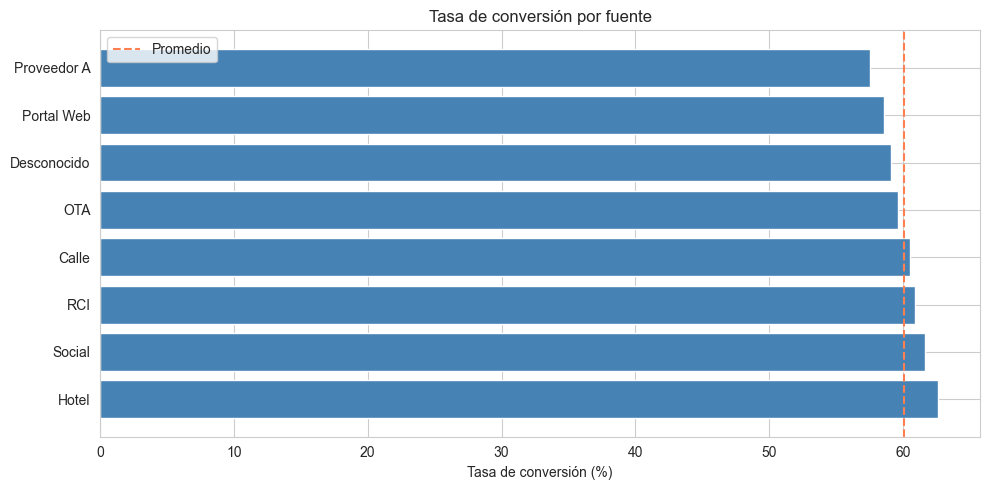

In [17]:
conversion = (
    df.groupby("fuente", dropna=False)
    .agg(
        leads  = ("lead_id",     "count"),
        ventas = ("fecha_venta", lambda x: x.notna().sum())
    )
    .assign(tasa_conversion = lambda x: (x["ventas"] / x["leads"] * 100).round(2))
    .sort_values("tasa_conversion", ascending=False)
)

print("=== Tasa de conversión por fuente (post-limpieza) ===")
print(conversion.to_string())

# Gráfica
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(conversion.index, conversion["tasa_conversion"], color="steelblue", edgecolor="white")
ax.set_xlabel("Tasa de conversión (%)")
ax.set_title("Tasa de conversión por fuente")
ax.axvline(conversion["tasa_conversion"].mean(), color="coral", linestyle="--", label="Promedio")
ax.legend()
plt.tight_layout()
plt.show()

### Celda 19 — VPG promedio por sala

VPG (*Valor Por Generado*) es la métrica de productividad por venta. Se calcula la media y mediana por sala para detectar si alguna sala tiene ventas con mayor valor unitario. La diferencia entre media y mediana indica asimetría (si la media es mucho mayor que la mediana, hay ventas de alto monto jalando el promedio hacia arriba).

> **Métrica de negocio:** permite identificar qué sala es más rentable por venta cerrada, independientemente de cuántas ventas haga.

=== VPG promedio por sala ===
                  vpg_medio  vpg_mediana  n_ventas
sala                                              
Cancún              4331.34      4389.94       854
Los Cabos           4224.63      4144.76       904
Playa del Carmen    4208.97      4232.11       624
Puerto Vallarta     4161.33      4006.63       614


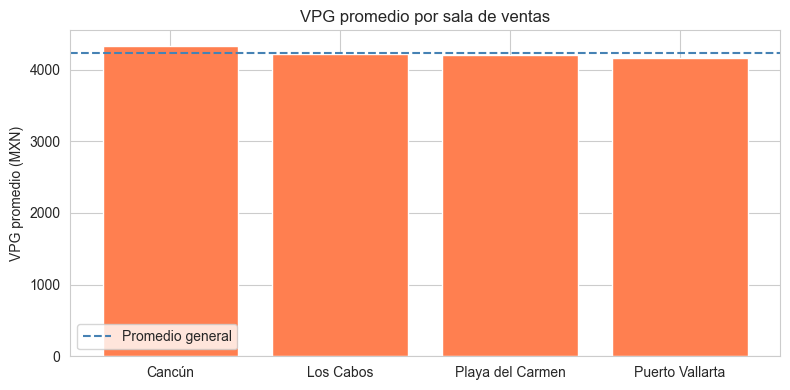

In [18]:
vpg_sala = (
    df.groupby("sala")["vpg"]
    .agg(["mean", "median", "count"])
    .rename(columns={"mean": "vpg_medio", "median": "vpg_mediana", "count": "n_ventas"})
    .round(2)
    .sort_values("vpg_medio", ascending=False)
)

print("=== VPG promedio por sala ===")
print(vpg_sala.to_string())

# Gráfica
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(vpg_sala.index, vpg_sala["vpg_medio"], color="coral", edgecolor="white")
ax.set_ylabel("VPG promedio (MXN)")
ax.set_title("VPG promedio por sala de ventas")
ax.axhline(vpg_sala["vpg_medio"].mean(), color="steelblue", linestyle="--", label="Promedio general")
ax.legend()
plt.tight_layout()
plt.show()

## Preguntas abiertas

### ¿Cómo manejarías duplicados que dependen de la sala?

Si un mismo `lead_id` aparece en dos salas distintas (por ejemplo, un lead
transferido de Cancún a Los Cabos), **no es un duplicado técnico sino un evento
de negocio**: el lead fue atendido por dos salas. La regla correcta es:

1. Identificar duplicados por `lead_id` + `sala` (no solo por `lead_id`).
2. Conservar **todos** los registros con sala diferente y marcarlos con una
   bandera `transferido = True`.
3. Eliminar solo los duplicados exactos en **todas** las columnas (misma sala,
   misma fecha, mismo monto).
4. Documentar la regla en el diccionario de datos para que no se trate como
   error en el futuro.

Este criterio se aplicó en la Fase 2: `drop_duplicates()` sobre todas las
columnas, preservando entradas con sala distinta.

---

### ¿Qué harías si no existe un diccionario de datos?

La ausencia de diccionario es el escenario real en sistemas legados como Oracle
11g sin documentación. El proceso de reconstrucción es:

1. **Inferencia por nombre y tipo**: el nombre de la columna + su tipo de dato
   + su distribución revelan la mayoría del significado (`monto` float → valor
   monetario; `vpg` float en rango 500–8000 → métrica de valor por venta).
2. **Entrevistas con usuarios del sistema**: los agentes y supervisores conocen
   el negocio; 1–2 sesiones de 30 minutos reemplazan semanas de reverse
   engineering.
3. **Trazabilidad hacia el origen**: seguir el flujo ETL (Oracle → CSV → CRM)
   para identificar transformaciones previas que distorsionen los datos.
4. **Documentar progresivamente**: cada columna analizada queda registrada en
   un diccionario provisional (`campo`, `tipo`, `descripción`, `nulos`,
   `rango`, `fuente`), que se valida con el equipo de negocio y se incorpora
   al README del proyecto.
5. **Marcar supuestos explícitos**: cuando el significado es incierto, se
   documenta el supuesto y se solicita confirmación antes de usar la variable
   en modelos.